In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Sample data.csv")

# Display first 5 rows
print("First 5 rows:")
display(df.head())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

First 5 rows:


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,NaN,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
1,Government,Germany,Paseo,NaN,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014
2,Government,Canada,Paseo,NaN,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,1-Nov-13,11,November,2013
3,Government,Germany,Paseo,NaN,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
4,Government,Germany,Velo,NaN,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014



Dataset shape: (700, 16)

Column names:
['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Segment              700 non-null    str    
 1   Country              700 non-null    str    
 2   Product              700 non-null    str    
 3   Discount Band        647 non-null    str    
 4   Units Sold           700 non-null    float64
 5   Manufacturing Price  700 non-null    int64  
 6   Sale Price           700 non-null    int64  
 7   Gross Sales          700 non-null    float64
 8   Discounts            700 non-null    float64
 9    Sales               700 non-null    float64
 10  COGS                 700 non-null 

In [17]:
# Step 2: Data Cleaning

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert Date column to proper datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing Discount Band values with "None"
df["Discount Band"] = df["Discount Band"].fillna("None")

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Remove duplicate rows if any
df = df.drop_duplicates()

# Check data types after cleaning
print("\nData types after cleaning:")
print(df.dtypes)

# Final dataset shape
print("\nDataset shape after cleaning:", df.shape)

# Display cleaned data
print("\nCleaned dataset:")
display(df.head())

Missing values before cleaning:
Series([], dtype: int64)

Duplicate rows found: 0
Missing values remaining: 0
Dataset shape: (700, 16)

Data cleaning completed successfully!


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,None,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
1,Government,Germany,Paseo,None,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014
2,Government,Canada,Paseo,None,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,2013-11-01,11,November,2013
3,Government,Germany,Paseo,None,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014
4,Government,Germany,Velo,None,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014


In [12]:
# Step 3: Exploratory Data Analysis (EDA)

# 1. Basic statistical summary
print("Statistical Summary:")
display(df.describe())

# 2. Total Sales
total_sales = df["Sales"].sum()

# 3. Total Profit
total_profit = df["Profit"].sum()

# 4. Total Units Sold
total_units = df["Units Sold"].sum()

# 5. Average Sales
average_sales = df["Sales"].mean()

print("\nKey Business Metrics:")
print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Units Sold: {total_units:,.0f}")
print(f"Average Sales per Record: {average_sales:,.2f}")

# 6. Sales by Country
print("\nSales by Country:")
sales_by_country = df.groupby("Country")["Sales"].sum().sort_values(ascending=False)
display(sales_by_country)

# 7. Sales by Segment
print("\nSales by Segment:")
sales_by_segment = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
display(sales_by_segment)

# 8. Sales by Product
print("\nSales by Product:")
sales_by_product = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)
display(sales_by_product)

# 9. Sales by Year
print("\nSales by Year:")
sales_by_year = df.groupby("Year")["Sales"].sum()
display(sales_by_year)

Statistical Summary:


,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Year
count,700.000000,700.000000,700.000000,7.000000e+02,700.000000,7.000000e+02,700.000000,700.000000,700,700.000000,700.000000
mean,1608.294286,96.477143,118.428571,1.827594e+05,13150.354629,1.696091e+05,145475.211429,24133.860371,2014-04-28 21:36:00,7.900000,2013.750000
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,-40617.500000,2013-09-01 00:00:00,1.000000,2013.000000
25%,905.000000,5.000000,12.000000,1.739175e+04,800.320000,1.592800e+04,7490.000000,2805.960000,2013-12-24 06:00:00,5.750000,2013.750000
50%,1542.500000,10.000000,20.000000,3.798000e+04,2585.250000,3.554020e+04,22506.250000,9242.200000,2014-05-16 12:00:00,9.000000,2014.000000
75%,2229.125000,250.000000,300.000000,2.790250e+05,15956.343750,2.610775e+05,245607.500000,22662.000000,2014-09-08 12:00:00,10.250000,2014.000000
max,4492.500000,260.000000,350.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,2014-12-01 00:00:00,12.000000,2014.000000
std,867.427859,108.602612,136.775515,2.542623e+05,22962.928775,2.367263e+05,203865.506118,42760.626563,NaN,3.377321,0.433322



Key Business Metrics:
Total Sales: 118,726,350.26
Total Profit: 16,893,702.26
Total Units Sold: 1,125,806
Average Sales per Record: 169,609.07

Sales by Country:


Country
United States of America    2.502983e+07
Canada                      2.488765e+07
France                      2.435417e+07
Germany                     2.350534e+07
Mexico                      2.094935e+07
Name: Sales, dtype: float64


Sales by Segment:


Segment
Government          5.250426e+07
Small Business      4.242792e+07
Enterprise          1.961169e+07
Midmarket           2.381883e+06
Channel Partners    1.800594e+06
Name: Sales, dtype: float64


Sales by Product:


Product
Paseo        3.301114e+07
VTT          2.051192e+07
Velo         1.825006e+07
Amarilla     1.774712e+07
Montana      1.539080e+07
Carretera    1.381531e+07
Name: Sales, dtype: float64


Sales by Year:


Year
2013    26415255.51
2014    92311094.75
Name: Sales, dtype: float64

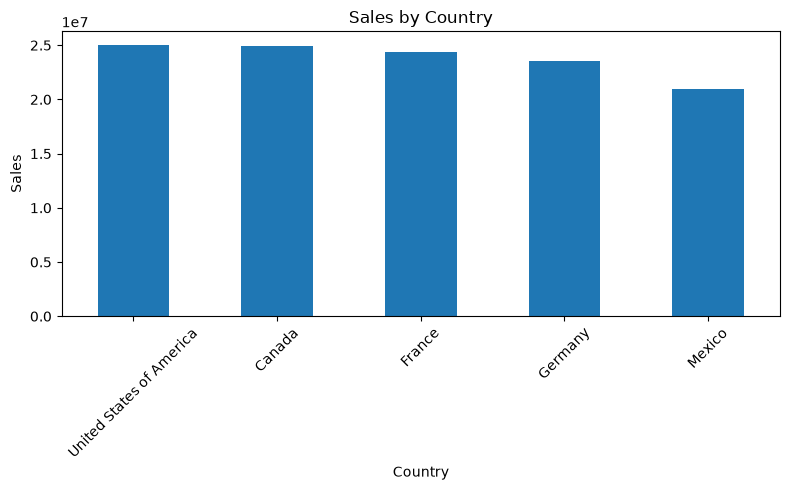

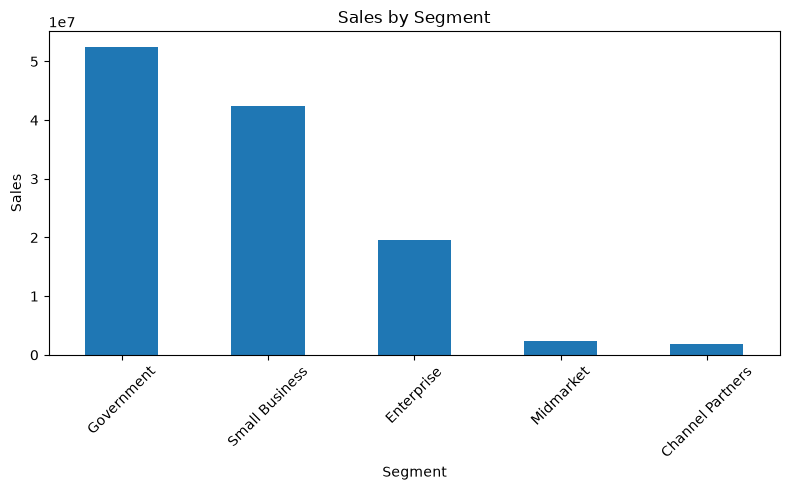

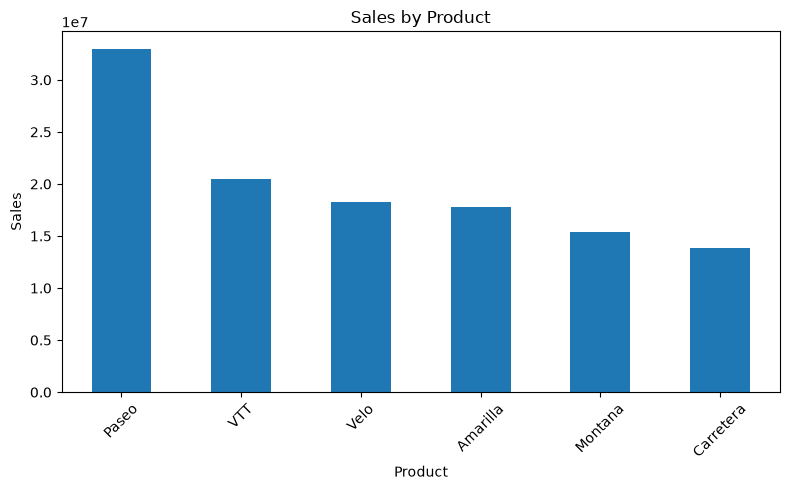

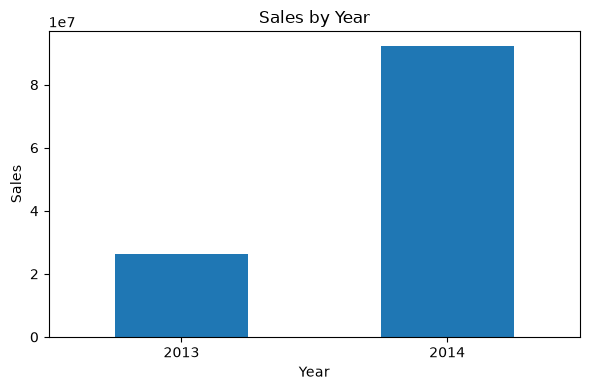

In [13]:
# Step 4: Sales Visualizations

# Sales by Country
plt.figure(figsize=(8, 5))
sales_by_country.plot(kind="bar")
plt.title("Sales by Country")
plt.xlabel("Country")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Sales by Segment
plt.figure(figsize=(8, 5))
sales_by_segment.plot(kind="bar")
plt.title("Sales by Segment")
plt.xlabel("Segment")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Sales by Product
plt.figure(figsize=(8, 5))
sales_by_product.plot(kind="bar")
plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Sales by Year
plt.figure(figsize=(6, 4))
sales_by_year.plot(kind="bar")
plt.title("Sales by Year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# Step 5: Regression Model

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select independent features
X = df[[
    "Units Sold",
    "Sale Price",
    "Manufacturing Price",
    "Month Number",
    "Year"
]]

# Target variable
y = df["Sales"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict Sales
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Regression Model Results:")
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"R² Score: {r2:.4f}")

Regression Model Results:
Mean Absolute Error (MAE): 83,139.20
Mean Squared Error (MSE): 13,051,282,466.61
R² Score: 0.7643


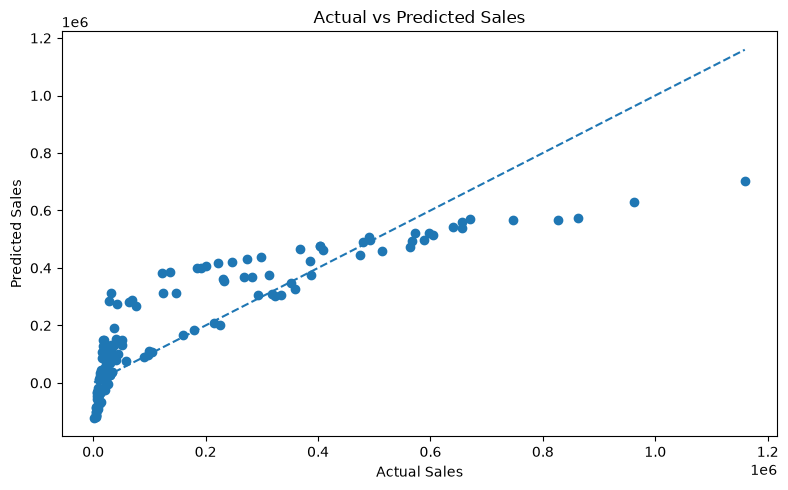

In [15]:
# Actual vs Predicted Sales

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()

In [16]:
# Save cleaned dataset for Power BI

df.to_csv("Sample data cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")
print("File name: Sample data cleaned.csv")

Cleaned dataset saved successfully.
File name: Sample data cleaned.csv
